# 03 — A címkék ellenőrzése / Validating the labels

HU: Valódi címke hiányában öt bizonyítékot gyűjtünk arról, hogy a BERT-címkék megbízhatóak:

| # | Bizonyíték / Evidence | Mit mutat? / What does it show? |
|---|---|---|
| 1 | Eloszlások / Distributions | mennyire térnek el a források / how the sources differ |
| 2 | Egyezés (kappa) / Agreement | a három megközelítés konzisztenciája / consistency of the three |
| 3 | Vendégpontszám / Guest score | konvergens validitás / convergent validity |
| 4 | Mezőpróba, HRAST-teszt / Field test, HRAST test | független ellenőrzés / independent checks |
| 5 | **Kézi gold minta / Manual gold sample** | **közvetlen pontosság / direct accuracy** |

Ez a notebook CPU-n, helyben fut (a 02 mentett eredményeiből). / Runs locally on a CPU (from the saved outputs of 02).

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import label_validation as lv
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

data = dl.read_frame(pipeline.LABELLED).set_index("review_id")
data["score_cut_label"] = lv.score_cut_labels(data["score"])     # HU/EN: REFERENCE ONLY
approaches = lv.available_approaches(data)
SOURCES = {**{f"{a}": f"{a}_label" for a in approaches}, "final": "label_final",
           "score cut (reference)": "score_cut_label"}
print(f"{len(data):,} reviews | approaches: {approaches}")

203,328 reviews | approaches: ['A', 'B', 'C']


## 1. Eloszlások / Distributions

,negative,neutral,positive,n
A,0.0340,0.0384,0.9276,203328
B,0.0571,0.1548,0.7881,203328
C,0.0216,0.3489,0.6295,203328
final,0.0571,0.1548,0.7881,203328
score cut (reference),0.1309,0.2243,0.6448,203328


17:57:50 | INFO    | src.evaluation | Table saved: 03_label_distribution.csv
17:57:50 | INFO    | src.evaluation | Figure saved: 03_label_distribution.png


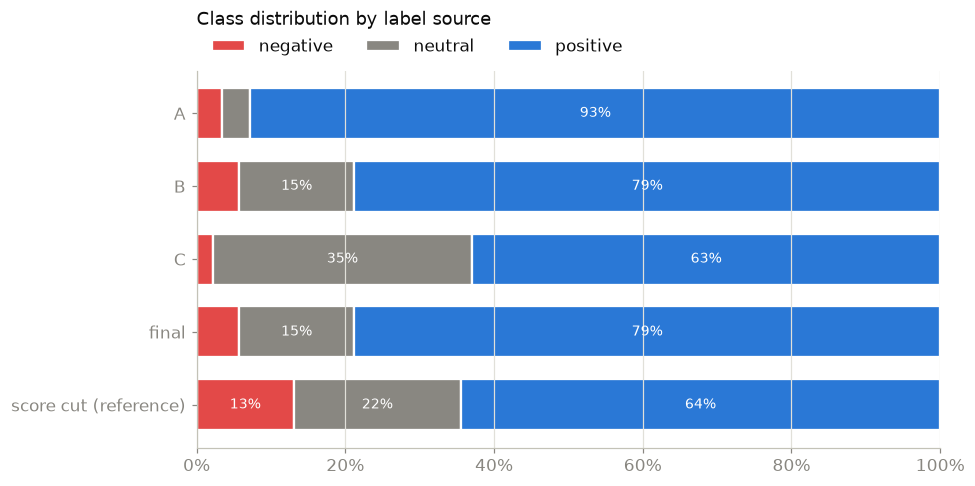

In [2]:
dist = lv.label_distribution(data, SOURCES)
display(dist)
ev.save_table(dist, "03_label_distribution")
lv.plot_label_distribution(dist, title="Class distribution by label source", save_as="03_label_distribution")
plt.show()

## 2. Egyezés a megközelítések között / Agreement between the approaches

HU: A (C) a saját tanítóvéleményein a tanárokat "visszamondja", ezért azokat kizárjuk (`comparison_mask`).
EN: On its own training reviews (C) "repeats" the teachers, so those are excluded (`comparison_mask`).

In [3]:
mask = lv.comparison_mask(data)
print(f"Rows used for agreement: {mask.sum():,} of {len(data):,}")
agreement = lv.pairwise_agreement(data[mask], SOURCES)
display(agreement)
ev.save_table(agreement, "03_pairwise_agreement")
fk = lv.fleiss_kappa(data[mask], [f"{a}_label" for a in approaches])
print(f"Fleiss' kappa ({', '.join(approaches)}): {fk:.3f}")

Rows used for agreement: 193,659 of 203,328


,n,agreement,cohen_kappa,weighted_kappa
pair,,,,
A vs B,193659,0.8047,0.2601,0.3604
A vs C,193659,0.6390,0.1231,0.1934
A vs final,193659,0.8047,0.2601,0.3604
A vs score cut (reference),193659,0.6564,0.1252,0.1707
B vs C,193659,0.7701,0.4966,0.5438
B vs final,193659,1.0000,1.0000,1.0000
B vs score cut (reference),193659,0.6615,0.2540,0.3257
C vs final,193659,0.7701,0.4966,0.5438
C vs score cut (reference),193659,0.6156,0.2597,0.3218


17:57:52 | INFO    | src.evaluation | Table saved: 03_pairwise_agreement.csv


Fleiss' kappa (A, B, C): 0.273


17:57:53 | INFO    | src.evaluation | Table saved: 03_crosstab_A_label_vs_B_label.csv
17:57:53 | INFO    | src.evaluation | Figure saved: 03_crosstab_A_label_vs_B_label.png


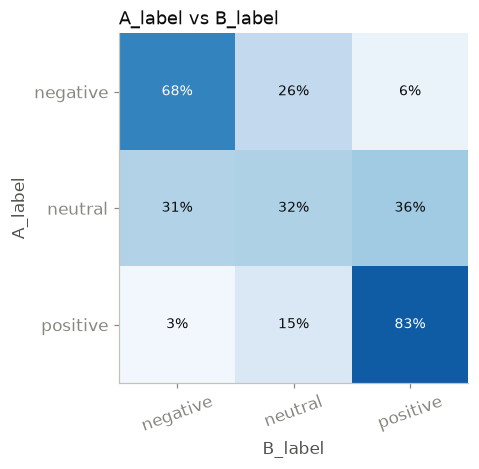

17:57:53 | INFO    | src.evaluation | Table saved: 03_crosstab_A_label_vs_C_label.csv
17:57:53 | INFO    | src.evaluation | Figure saved: 03_crosstab_A_label_vs_C_label.png


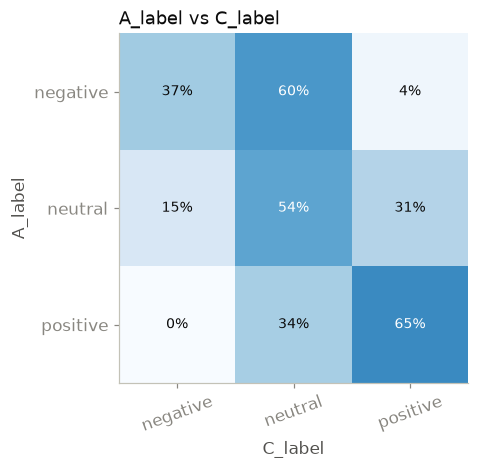

17:57:54 | INFO    | src.evaluation | Table saved: 03_crosstab_label_final_vs_score_cut_label.csv
17:57:54 | INFO    | src.evaluation | Figure saved: 03_crosstab_label_final_vs_score_cut_label.png


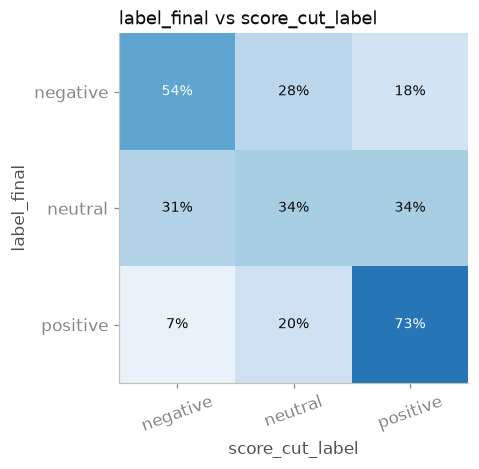

In [4]:
pairs = [("A_label", "B_label"), ("A_label", "C_label"), ("label_final", "score_cut_label")]
for col_a, col_b in pairs:
    if {col_a, col_b} <= set(data.columns):
        tab = lv.approach_crosstab(data[mask], col_a, col_b)
        name = f"03_crosstab_{col_a}_vs_{col_b}"
        ev.save_table(tab, name)
        lv.plot_agreement_matrix(tab, f"{col_a} vs {col_b}", xlabel=col_b, ylabel=col_a, save_as=name)
        plt.show()

## 3. Kapcsolat a vendégpontszámmal / Relation to the guest score

HU: Erős, de **nem tökéletes** kapcsolat a jó eredmény. A `neg_but_score_ge9` oszlop mutatja, hányszor panaszkodik a
szöveg magas pontszám mellett — ezt a pontszám-vágás nem látná.
EN: A strong but **imperfect** relation is the good outcome. `neg_but_score_ge9` shows how often the text complains
despite a high score — a score cut would miss this.

,spearman_rho,mean_guest_score_negative,mean_guest_score_neutral,mean_guest_score_positive,neg_but_score_ge9,pos_but_score_le6
approach,,,,,,
A,0.5729,7.1988,7.9746,8.9688,0.0046,0.0168
B,0.4392,7.4291,8.0680,9.1326,0.0106,0.0067
C,0.4848,7.3828,8.2470,9.2671,0.0042,0.0035
final,0.4392,7.4291,8.0680,9.1326,0.0106,0.0067


17:57:54 | INFO    | src.evaluation | Table saved: 03_guest_score_validity.csv
17:57:54 | INFO    | src.evaluation | Figure saved: 03_text_score_vs_guest_score.png


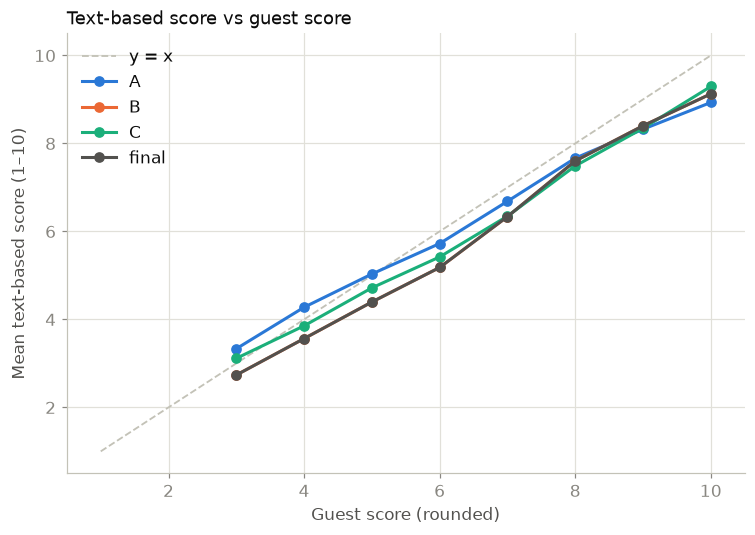

In [5]:
# HU: A végső címkét is "megközelítésként" kezeljük. / EN: The final label is treated as an "approach" too.
data["final_label"], data["final_score_cont"] = data["label_final"], data["score_cont_final"]
validity = lv.guest_score_validity(data, approaches + ["final"])
display(validity)
ev.save_table(validity, "03_guest_score_validity")
lv.plot_score_vs_guest(data, approaches + ["final"], save_as="03_text_score_vs_guest_score")
plt.show()

17:57:55 | INFO    | src.evaluation | Figure saved: 03_text_score_vs_guest_score.png


<Axes: title={'left': 'Text-based score vs guest score'}, xlabel='Guest score (rounded)', ylabel='Mean text-based score (1–10)'>

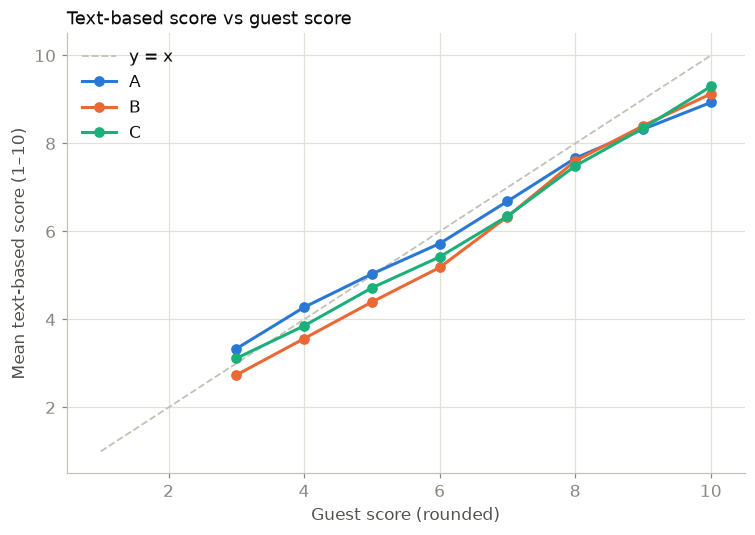

In [6]:
lv.plot_score_vs_guest(data, approaches, save_as="03_text_score_vs_guest_score")

In [7]:
# HU: Ahol a szöveg és a pontszám nagyon eltér — olvasd el, és válassz idézeteket a dolgozatba.
# EN: Where text and score differ strongly — read them and pick quotes for the thesis.
disc = lv.text_score_discrepancies(data.reset_index(), min_gap=4, n_examples=12)
ev.save_table(disc, "03_text_score_discrepancies")
for _, r in disc.iterrows():
    print(f"[guest {r['score']:.0f} | text {r['score10_final']} | {r['label_final']}]  {r['text'][:230]}\n")

17:57:55 | INFO    | src.label_validation | Reviews with |text score − guest score| ≥ 4: 14038 (6.90%)
17:57:55 | INFO    | src.evaluation | Table saved: 03_text_score_discrepancies.csv


[guest 5 | text 1 | negative]  Good customer service via phone The first room had issues (with the toilet flush and the kitchen sink) and they changed to 2nd room to solve those issues very close to the metro station, stores, a few restaurants, a few bars aroun

[guest 10 | text 6 | neutral]  Was nice comfortable bed and room was very nice. Highway noise

[guest 9 | text 5 | neutral]  Great time in Savannah, would return and stay here again! Perfect Location! Great breakfast! Parking! Lot is so small that it was hard to find anything and than to be charged $25 a night. I got a call about where we parked one nig

[guest 6 | text 10 | positive]  Okay stay. Location is great, Breakfast was pleasant ,view was perfect montain and pool,good dj for daily music , room was fine , with bigg balcony and small balcony,friendly staf.clean swimming pool Rooms must be more maintained,

[guest 8 | text 4 | negative]  Clean, newly renovated rooms and great location! Hottub was closed. Also the tvs were

## 4. Független próbák / Independent checks

In [8]:
for name in ["02_field_test", "02_approach_b_hrast_test"]:
    path = PATHS.tables / f"{name}.csv"
    if path.exists():
        print(f"=== {name} ===")
        display(pd.read_csv(path))
    else:
        print(f"{name}: not available (run notebook 02).")

=== 02_field_test ===


,approach,field,n,hit,neutral,opposite
0,A,review_negative,2000,0.4995,0.3520,0.1485
1,A,review_positive,2000,0.9605,0.0325,0.0070
2,C,review_negative,2000,0.6645,0.2460,0.0895
3,C,review_positive,2000,0.9420,0.0490,0.0090
4,B,review_negative,2000,0.7745,0.0990,0.1265
5,B,review_positive,2000,0.9790,0.0050,0.0160


=== 02_approach_b_hrast_test ===


,Unnamed: 0,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,HRAST test,0.9414,0.7731,0.7825,0.7776,0.9431,0.9414,0.9422


## 5. Kézi gold minta / Manual gold sample

HU: Az **egyetlen közvetlen pontosságmérés**. Lépések:
1. az alábbi cella exportálja a `data/annotation/gold_sample_to_annotate.csv` fájlt (csak szöveg — **vak** annotálás);
2. töltsd ki a `gold_label` (negative / neutral / positive) és a `gold_score` (1–10) oszlopot a `docs/ANNOTATION_GUIDE.md` szerint;
3. futtasd újra a cellát → összevetés minden forrással, a **pontszám-vágással együtt**.

EN: The **only direct accuracy measurement**. Export → annotate blind (`docs/ANNOTATION_GUIDE.md`) → re-run → comparison
with every source, **including the score cut**.

In [9]:
#from src import label_validation as lv
#lv.gold_csv_to_xlsx()

In [10]:
gold_file = PATHS.annotation / "gold_sample_to_annotate.csv"
if not gold_file.exists():
    lv.export_gold_sample(data.reset_index())
    print("Exported. Annotate it, then re-run this cell.")
else:
    gold = lv.load_gold()
    if len(gold) == 0:
        print("The gold file exists but has no valid gold_label yet.")
    else:
        score_cols = {**{a: f"{a}_score_cont" for a in approaches}, "final": "score_cont_final",
                      "score cut (reference)": "score"}
        gold_eval = lv.evaluate_on_gold(gold, data, SOURCES, score_cols)
        display(gold_eval)
        ev.save_table(gold_eval, "03_gold_evaluation")
        print("=> Set CFG.tie_breaker_approach in config.py to the best approach.")

17:57:56 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
17:57:56 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
17:57:56 | INFO    | src.label_validation | Gold reviews matched with labels: 399


,n,accuracy,f1_macro,cohen_kappa,score_mae
source,,,,,
B,399,0.8045,0.6405,0.5046,1.0497
final,399,0.8045,0.6405,0.5046,1.0497
score cut (reference),399,0.7168,0.5615,0.3797,1.3810
A,399,0.8045,0.5494,0.3369,1.1611
C,399,0.7318,0.5351,0.4234,1.1858


17:57:56 | INFO    | src.evaluation | Table saved: 03_gold_evaluation.csv


=> Set CFG.tie_breaker_approach in config.py to the best approach.


17:57:56 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
17:57:56 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.00 -> {'positive': 0.91, 'negative': 0.09}
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.10 -> {'positive': 0.832, 'neutral': 0.088, 'negative': 0.08}
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.15 -> {'positive': 0.807, 'neutral': 0.12, 'negative': 0.073}
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.20 -> {'positive': 0.787, 'neutral': 0.153, 'negative': 0.06}
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.25 -> {'positive': 0.764, 'neutral': 0.178, 'negative': 0.058}
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.30 -> {'positive': 0.752, 'neutral': 0.203, 'negative': 0.045}
17:57:56 | INFO    | src.bert_labelling | (B) neutral band ±0.35 -> {'positive': 0.674

,accuracy,f1_macro,cohen_kappa,f1_neutral,share_neutral
band,,,,,
0.00,0.8145,0.5292,0.4002,0.0000,0.0000
0.10,0.8095,0.6134,0.4638,0.2947,0.0877
0.15,0.8095,0.6326,0.4850,0.3519,0.1203
0.20,0.8095,0.6391,0.5004,0.4132,0.1529
0.25,0.8045,0.6405,0.5046,0.4427,0.1779
0.30,0.8020,0.6312,0.5069,0.4681,0.2030
0.35,0.7594,0.5786,0.4622,0.4746,0.2932
0.40,0.7569,0.5824,0.4691,0.4891,0.3108
0.50,0.7218,0.5478,0.4296,0.4757,0.3659


17:57:56 | INFO    | src.evaluation | Table saved: 03_neutral_band_calibration.csv


,f1_macro_low,f1_macro_high,accuracy_low,accuracy_high
source,,,,
A,0.4760,0.6146,0.7644,0.8446
B,0.5706,0.7061,0.7644,0.8421
C,0.4671,0.6037,0.6867,0.7744
final,0.5726,0.7040,0.7669,0.8421
score cut (reference),0.5002,0.6239,0.6717,0.7619


17:58:28 | INFO    | src.evaluation | Table saved: 03_gold_bootstrap_ci.csv


,precision,recall,f1-score,support
negative,0.783,0.450,0.571,40.000
neutral,0.408,0.483,0.443,60.000
positive,0.898,0.916,0.907,299.000
accuracy,0.805,0.805,0.805,0.805
macro avg,0.696,0.617,0.640,399.000
weighted avg,0.813,0.805,0.804,399.000


17:58:29 | INFO    | src.evaluation | Figure saved: 03_B_vs_gold_confusion.png


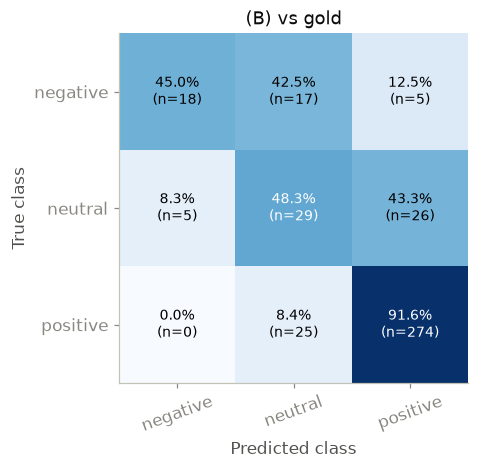

In [11]:
from src import bert_labelling as bl

labels_b = bl.load_labels("labels_B")
gold = lv.load_gold()

# 1) HU: Semleges sáv kalibrálása / EN: Neutral band calibration
calib = lv.calibrate_neutral_band(gold, labels_b, "B")
display(calib); ev.save_table(calib, "03_neutral_band_calibration")

# 2) HU: 95%-os bootstrap-intervallumok / EN: 95% bootstrap intervals
ci = lv.bootstrap_ci(gold, data, SOURCES)
display(ci); ev.save_table(ci, "03_gold_bootstrap_ci")

# 3) HU: Hol hibázik a (B)? / EN: Where does (B) make mistakes?
joined = gold.join(data, how="inner", rsuffix="_lbl")
display(ev.per_class_report(joined["gold_label"], joined["B_label"]).round(3))
ev.plot_confusion_matrix(joined["gold_label"], joined["B_label"], title="(B) vs gold",
                         save_as="03_B_vs_gold_confusion"); plt.show()

In [12]:
   from src import pipeline
   from src.config import CFG
   labels_b = bl.apply_neutral_band(bl.load_labels("labels_B"), "B", CFG.review_neutral_band)
   bl.save_labels(labels_b, "labels_B")
   labelled = pipeline.step_combine()

17:58:29 | INFO    | src.bert_labelling | (B) neutral band ±0.25 -> {'positive': 0.788, 'neutral': 0.155, 'negative': 0.057}
17:58:29 | INFO    | src.bert_labelling | Labels saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\labels\labels_B.parquet (203328 rows)
17:58:29 | INFO    | src.bert_labelling | Combining approaches: ['B'] (tie-breaker: B)
17:59:47 | INFO    | src.bert_labelling | Labels saved: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\labels\labels_final.parquet (203328 rows)
17:59:49 | INFO    | src.pipeline | Final label distribution: {'positive': 0.788, 'neutral': 0.155, 'negative': 0.057}


In [13]:
from src import bert_labelling as bl, pipeline

# HU: Többségi szavazás (A+B+C) számolása CSAK összehasonlításra, mentés nélkül.
# EN: Majority vote (A+B+C) computed ONLY for comparison, without saving.
vote = bl.combine_approaches(pipeline._load_available_labels(),
                             approaches=("A", "B", "C"), tie_breaker="B")
data["vote_label"] = vote["label_final"]
data["vote_score_cont"] = vote["score_cont_final"]

sources = {**SOURCES, "vote A+B+C": "vote_label"}
score_cols = {**{a: f"{a}_score_cont" for a in approaches},
              "vote A+B+C": "vote_score_cont", "score cut (reference)": "score"}
cmp = lv.evaluate_on_gold(lv.load_gold(), data, sources, score_cols)
display(cmp); ev.save_table(cmp, "03_gold_B_vs_vote")
print(f"B and the vote agree on {(data['B_label'] == data['vote_label']).mean():.1%} of the reviews")

score_cols = {**{a: f"{a}_score_cont" for a in approaches}, "final": "score_cont_final",
              "vote A+B+C": "vote_score_cont", "score cut (reference)": "score"}

17:59:50 | INFO    | src.bert_labelling | Combining approaches: ['A', 'B', 'C'] (tie-breaker: B)
18:01:23 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
18:01:23 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
18:01:23 | INFO    | src.label_validation | Gold reviews matched with labels: 399


,n,accuracy,f1_macro,cohen_kappa,score_mae
source,,,,,
B,399,0.8045,0.6405,0.5046,1.0497
final,399,0.8045,0.6405,0.5046,NaN
vote A+B+C,399,0.8045,0.6403,0.4988,0.9956
score cut (reference),399,0.7168,0.5615,0.3797,1.3810
A,399,0.8045,0.5494,0.3369,1.1611
C,399,0.7318,0.5351,0.4234,1.1858


18:01:23 | INFO    | src.evaluation | Table saved: 03_gold_B_vs_vote.csv


B and the vote agree on 98.0% of the reviews


In [14]:
data["B_label"].value_counts(normalize=True).round(3)

B_label
positive    0.788
neutral     0.155
negative    0.057
Name: proportion, dtype: float64